In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d
import pycolmap

pycolmap.logging.minloglevel = 2

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


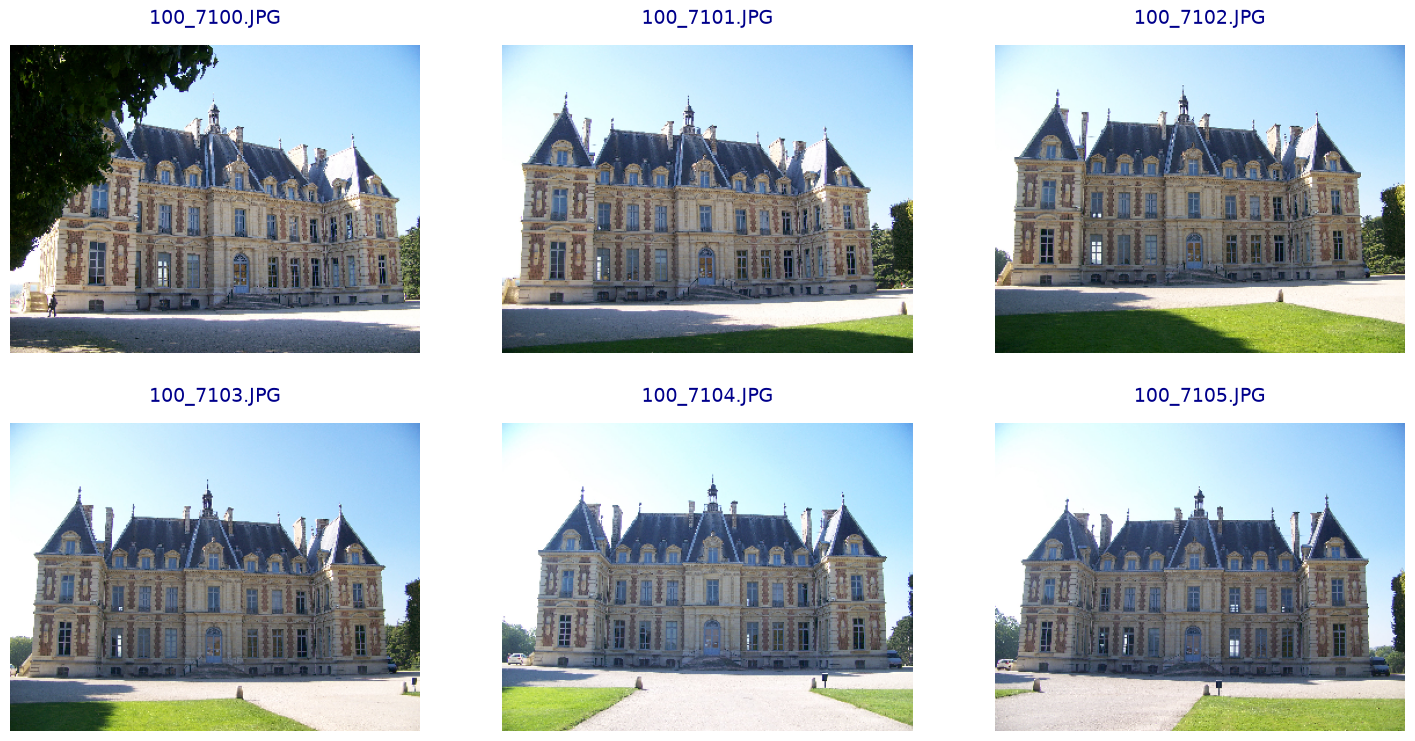

In [2]:
images = 'castle'
out = 'output/colmap'
os.makedirs(out, exist_ok=True)
db = f'{out}/database.db'
if os.path.exists(db):
    os.remove(db)

names = sorted(os.listdir(images))
panels = [(n, cv2.imread(f'{images}/{n}', cv2.IMREAD_COLOR_RGB)[::8, ::8]) for n in names[:6]]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

for ax in axes[len(panels):]:
    ax.axis('off')

plt.show()

In [3]:
# features
opts = pycolmap.FeatureExtractionOptions()
opts.max_image_size = 1024
opts.sift.max_num_features = 4000
pycolmap.extract_features(db, images, camera_mode=pycolmap.CameraMode.SINGLE, extraction_options=opts)

In [4]:
# matching
pycolmap.match_exhaustive(db)

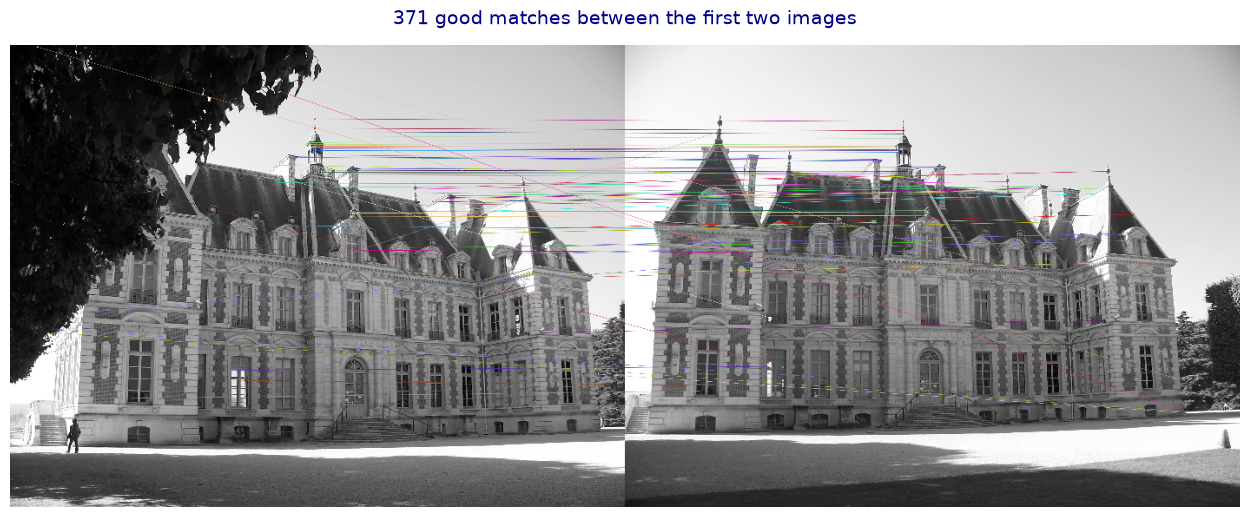

In [5]:
# matches of one pair
a, b = (cv2.imread(f'{images}/{n}', cv2.IMREAD_GRAYSCALE) for n in names[:2])
sift = cv2.SIFT_create(4000)
(ka, da), (kb, db_) = sift.detectAndCompute(a, None), sift.detectAndCompute(b, None)
pairs = cv2.BFMatcher().knnMatch(da, db_, k=2)
good = [m for m, n in pairs if m.distance < 0.7 * n.distance]
vis = cv2.drawMatches(a, ka, b, kb, good[:80], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(18, 6))
plt.imshow(vis[::4, ::4], cmap='gray')
plt.axis('off')
plt.title(f'{len(good)} good matches between the first two images', fontsize=14, color='darkblue', pad=15)
plt.show()

In [6]:
# poses and sparse points
recs = pycolmap.incremental_mapping(db, images, f'{out}/sparse')
rec = recs[0]
print(rec.summary())

Reconstruction:
	num_rigs = 1
	num_cameras = 1
	num_frames = 11
	num_reg_frames = 11
	num_images = 11
	num_points3D = 4588
	num_observations = 23294
	mean_track_length = 5.07716
	mean_observations_per_image = 2117.64
	mean_reprojection_error = 0.721997


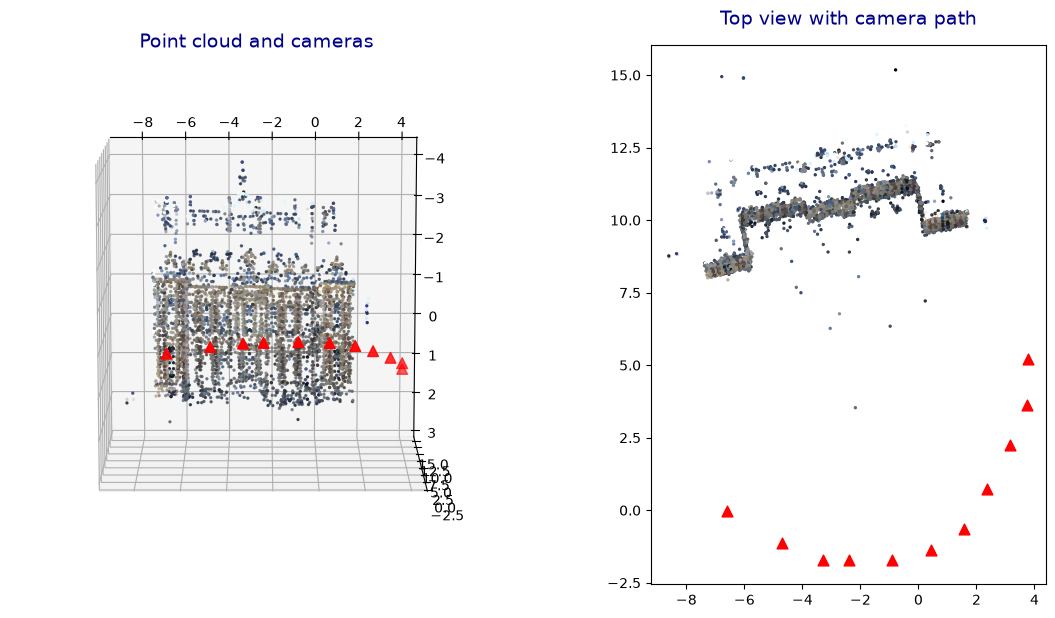

In [7]:
centers = np.array([im.projection_center() for im in rec.images.values()])
pts = np.array([p.xyz for p in rec.points3D.values()])
cols = np.array([p.color for p in rec.points3D.values()]) / 255

keep = np.linalg.norm(pts - np.median(pts, axis=0), axis=1) < 3 * np.median(np.linalg.norm(pts - np.median(pts, axis=0), axis=1))
pts, cols = pts[keep], cols[keep]

fig = plt.figure(figsize=(14, 7))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter(*pts.T, c=cols, s=2)
ax.scatter(*centers.T, c='red', marker='^', s=60)
ax.view_init(elev=-80, azim=-90)
ax.set_title('Point cloud and cameras', fontsize=14, color='darkblue', pad=15)

ax = fig.add_subplot(1, 2, 2)
ax.scatter(pts[:, 0], pts[:, 2], c=cols, s=2)
ax.scatter(centers[:, 0], centers[:, 2], c='red', marker='^', s=60)
ax.set_aspect('equal')
ax.set_title('Top view with camera path', fontsize=14, color='darkblue', pad=15)

plt.show()

In [8]:
# mesh
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(pts)
pcd.colors = o3d.utility.Vector3dVector(cols)
pcd, _ = pcd.remove_statistical_outlier(20, 2.0)
pcd.estimate_normals(o3d.geometry.KDTreeSearchParamKNN(30))
pcd.orient_normals_consistent_tangent_plane(30)

mesh, dens = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(pcd, depth=7)
mesh.remove_vertices_by_mask(np.asarray(dens) < np.quantile(dens, 0.1))
print(pcd, mesh)

o3d.io.write_point_cloud(f'{out}/cloud.ply', pcd)
o3d.io.write_triangle_mesh(f'{out}/mesh.ply', mesh)

PointCloud with 4544 points. TriangleMesh with 9607 points and 18878 triangles.


True

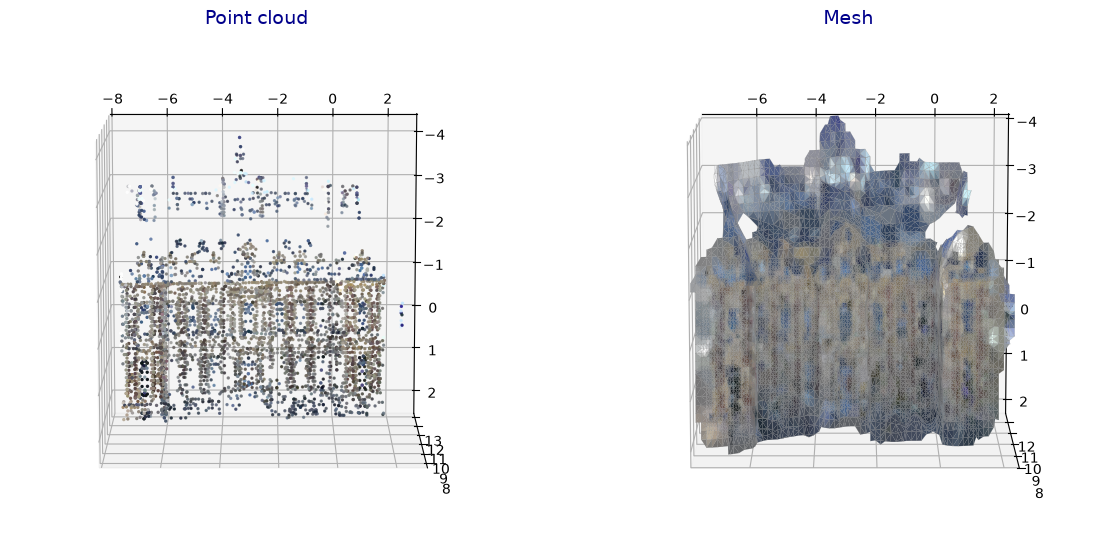

In [9]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

v, f = np.asarray(mesh.vertices), np.asarray(mesh.triangles)
vc = np.asarray(mesh.vertex_colors)
face_col = vc[f].mean(axis=1) if len(vc) else 'lightgray'

fig = plt.figure(figsize=(14, 7))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter(*np.asarray(pcd.points).T, c=np.asarray(pcd.colors), s=2)
ax.view_init(elev=-80, azim=-90)
ax.set_title('Point cloud', fontsize=14, color='darkblue', pad=15)

ax = fig.add_subplot(1, 2, 2, projection='3d')
ax.add_collection3d(Poly3DCollection(v[f], facecolors=face_col, linewidths=0.1, edgecolors='gray'))
ax.set_xlim(v[:, 0].min(), v[:, 0].max())
ax.set_ylim(v[:, 1].min(), v[:, 1].max())
ax.set_zlim(v[:, 2].min(), v[:, 2].max())
ax.view_init(elev=-80, azim=-90)
ax.set_title('Mesh', fontsize=14, color='darkblue', pad=15)

plt.show()